# Лабораторная работа № 9. Использование разработанного пайплайна для многомерной регрессии
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** научиться применять разработанный пайплайн для тиражирования кода с целью решения широкого круга задач машинного обучения.

**Задачи:** освоить рефакторинг, определение ключевых признаков и основные стратегии оптимизации регрессии.

**Данные:** `50_Startups.csv` для учебного примера; прежний RCAEval RE2-OB для индивидуального задания.

Работа выполнена по лабораторной № 9 методички *Practicum_AI_Methods.pdf*, с. 96–102.

## 1. Локальный запуск и общий шаблон
Используем прежнее Conda-окружение `rcaeval-ai`. В VS Code выбираем его ядро и выполняем **Run All**. Для работы № 9 в `environment.yml` добавлен `statsmodels=0.14`. Обновить окружение из корня можно командой:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```

Ноутбук работает из корня проекта и из `notebooks/`. RCAEval уже сохранён на компьютере; повторное скачивание не выполняется. Таблицы и рисунки записываются в папку этой работы внутри `reports/`.

**Пайплайн** — последовательность шагов, которая одинаково готовит обучающие данные и новые строки. Сначала отделяем проверочные данные, затем вызываем `fit` только для обучения. Для проверки используются сохранённые средние, масштаб и категории.

Подключаем библиотеки для таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем средства подготовки данных и регрессии.

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm
from sklearn.base import BaseEstimator, RegressorMixin

Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab09'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
EXAMPLES = ROOT / 'data/raw/pipeline_examples'
EXAMPLES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn', 'statsmodels']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
pandas            2.3.3
numpy             2.2.6
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn      1.7.2
statsmodels      0.14.6
Name: Версия, dtype: object

169

Определяем функцию сохранения и показа рисунков.

In [5]:
def save_show(fig, name):
    fig.savefig(FIGURES / name, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 1.1. Переиспользуемый шаблон подготовки
Для числовых столбцов заполняем пропуски средним значением обучения. Масштабирование можно включить или отключить. `StandardScaler` вычитает среднее и делит на стандартное отклонение.

Для категорий заполняем пропуски наиболее частой категорией и используем `OneHotEncoder`: отдельные столбцы 0/1. Одну категорию оставляем базовой (`drop='first'`), чтобы вместе со свободным членом не создавать избыточные столбцы. Названия преобразованных признаков сохраняются.

Эта функция одинаковая в работах № 7, 8 и 9. Для новой задачи меняются списки столбцов и последний шаг модели. Каждый ноутбук содержит её определение и запускается самостоятельно.

Определяем общий шаблон предварительной обработки.

In [6]:
def make_preprocessor(numeric, categorical, scale=True):
    numeric_steps = [('impute', SimpleImputer(strategy='mean'))]
    if scale:
        numeric_steps.append(('scale', StandardScaler()))
    categorical_steps = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), numeric),
        ('categorical', categorical_steps, categorical)
    ], verbose_feature_names_out=False).set_output(transform='pandas')

Определяем функцию расчёта ошибок регрессии.

In [7]:
def regression_scores(actual, predicted):
    return {'MSE': mean_squared_error(actual, predicted),
            'MAE': mean_absolute_error(actual, predicted),
            'R2': r2_score(actual, predicted)}

Многомерная регрессия здесь означает **несколько входных признаков и один числовой ответ**. Стратегия **all-in** использует все выбранные признаки. **Backward elimination** начинает с них же и последовательно удаляет признак с наибольшим p-значением, пока оставшиеся проходят заданный порог.

Порог заранее задаём как 0,05. Большое p-значение означает, что в текущей модели недостаточно оснований отличить коэффициент от нуля при предположениях теста. Оно не доказывает бесполезность признака вообще. Отбор выполняется только по обучению и не гарантирует уменьшения ошибки на новых строках.

Общий шаблон подготовки из работы № 7 сохраняется. К LinearRegression добавляем шаг, который обучает OLS и автоматически сокращает набор признаков. Категории кодируются с одной базовой категорией, а свободный член задаётся столбцом единиц.

Определяем обучение OLS с постоянным свободным членом.

In [8]:
def fit_ols(X, y, groups=None):
    design = X.copy()
    design.insert(0, 'const', 1.0)
    model = sm.OLS(np.asarray(y, dtype=float), design)
    if groups is None:
        return model.fit()
    return model.fit(cov_type='cluster', cov_kwds={'groups': np.asarray(groups)}, use_t=True)

Константа `const = 1` позволяет модели подобрать свободный член. Для обычного учебного примера используем стандартный расчёт p-значений. Для RCAEval передаём минутные группы: расчёт учитывает сходство строк внутри минуты. Коэффициенты по-прежнему подбираются методом наименьших квадратов.

Определяем автоматическое исключение признаков.

In [9]:
def backward_elimination(X, y, alpha=0.05, groups=None):
    columns = X.columns.tolist()
    history = []
    while True:
        result = fit_ols(X[columns], y, groups)
        pvalues = result.pvalues.drop('const')
        if pvalues.empty:
            break
        worst = pvalues.idxmax()
        remove = float(pvalues[worst]) > alpha
        history.append({'step': len(history) + 1, 'features': ', '.join(columns),
                        'max_p': float(pvalues[worst]), 'worst': worst,
                        'removed': worst if remove else 'нет'})
        if not remove:
            break
        columns.remove(worst)
    return columns, pd.DataFrame(history), result

На каждом шаге модель обучается заново: после удаления одного признака p-значения других могут измениться. Константу не удаляем. Если все признаки исключены, остаётся модель с одним свободным членом. История показывает все удаления и последнюю проверку.

Встраиваем отбор и OLS в один шаг пайплайна.

In [10]:
class BackwardOLS(RegressorMixin, BaseEstimator):
    def __init__(self, alpha=0.05):
        self.alpha = alpha

    def fit(self, X, y, groups=None):
        self.columns_, self.history_, self.result_ = backward_elimination(X, y, self.alpha, groups)
        return self

    def predict(self, X):
        design = X[self.columns_].copy()
        design.insert(0, 'const', 1.0)
        return self.result_.predict(design).to_numpy()

Небольшой класс нужен, чтобы весь отбор запускался при `Pipeline.fit`. При `predict` он использует уже выбранные признаки и веса. Проверочные ответы для удаления признаков не используются. Так можно применять один шаблон к разным таблицам, меняя списки столбцов.

Определяем функцию создания пайплайна с автоматическим отбором.

In [11]:
def make_backward_pipeline(numeric, categorical=(), alpha=0.05):
    return Pipeline([
        ('prepare', make_preprocessor(list(numeric), list(categorical), scale=True)),
        ('regression', BackwardOLS(alpha=alpha))
    ])

## 2. Учебная задача: прибыль 50 компаний
### 2.1. Данные и кодирование категории
Воспроизводим пример рис. 9.1–9.2. Числовые признаки — расходы на R&D, Administration и Marketing Spend; категория — State; ответ — Profit. Это учебная таблица из примера, а не индивидуальный датасет мониторинга.

Порядок обработки сохраняет отложенные 20% строк: кодирование, масштаб и исключение признаков обучаются по остальным 80%. В отличие от листинга с OLS по всем 50 строкам, результаты подбора здесь относятся только к обучению.

Получаем учебный CSV, если его ещё нет на компьютере.

In [12]:
example_path = EXAMPLES / '50_Startups.csv'
example_revision = '66d3cdbd8a19102c54750d8e8bd834845c7eedef'
example_url = f'https://raw.githubusercontent.com/murphymv/Machine-Learning-A-Z/{example_revision}/50_Startups.csv'
if not example_path.exists():
    example_path.write_bytes(urlopen(example_url, timeout=60).read())

Читаем учебную таблицу.

In [13]:
startups = pd.read_csv(example_path)

Печатаем первые строки, размеры и пропуски.

In [14]:
display(startups.head())
print('Размер:', startups.shape)
display(startups.isna().sum().rename('Пропуски'))

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


Размер: (50, 5)


R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
Name: Пропуски, dtype: int64

Выделяем признаки и делим таблицу, как в примере.

In [15]:
startup_numeric = ['R&D Spend', 'Administration', 'Marketing Spend']
startup_categorical = ['State']
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    startups[startup_numeric + startup_categorical], startups.Profit, test_size=0.2, random_state=0)

Обучаем модель all-in с общим шаблоном подготовки.

In [16]:
startup_all = Pipeline([
    ('prepare', make_preprocessor(startup_numeric, startup_categorical)),
    ('regression', LinearRegression())
]).fit(Xs_train, ys_train)
startup_ready = startup_all.named_steps['prepare'].transform(Xs_train)
display(startup_ready.head())
print('Базовый State:', startup_all.named_steps['prepare'].named_transformers_['categorical'].named_steps['encode'].categories_[0][0])

,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
33,-0.350065,-0.785471,0.101197,1.0,0.0
35,-0.555303,-1.481174,0.027350,0.0,1.0
26,0.079358,0.801334,-0.551521,1.0,0.0
34,-0.546382,1.325058,0.070117,0.0,0.0
18,0.434854,-0.355987,0.751485,1.0,0.0


Базовый State: California


Три числовых признака масштабированы. Для трёх значений State создаются два столбца 0/1. Базовый State задаётся нулями в этих столбцах. Это устраняет точную зависимость «сумма всех трёх индикаторов равна константе».

Обучаем OLS на всех подготовленных признаках и показываем p-значения.

In [17]:
startup_ols_all = fit_ols(startup_ready, ys_train)
display(pd.DataFrame({'Вес': startup_ols_all.params, 'p-значение': startup_ols_all.pvalues}))

,Вес,p-значение
const,109441.489122,1.190074e-31
R&D Spend,35726.287742,1.068698e-15
Administration,851.301634,6.239644e-01
Marketing Spend,4519.882777,6.807739e-02
State_Florida,-959.284160,8.136498e-01
State_New York,699.369053,8.496593e-01


Запускаем автоматическое backward elimination на обучении.

In [18]:
ALPHA = 0.05
startup_backward = make_backward_pipeline(startup_numeric, startup_categorical, ALPHA).fit(Xs_train, ys_train)
startup_selected = startup_backward.named_steps['regression']
display(startup_selected.history_)
print('Остались:', startup_selected.columns_)

,step,features,max_p,worst,removed
0,1,"R&D Spend, Administration, Marketing Spend, St...",8.496593e-01,State_New York,State_New York
1,2,"R&D Spend, Administration, Marketing Spend, St...",7.287964e-01,State_Florida,State_Florida
2,3,"R&D Spend, Administration, Marketing Spend",6.496047e-01,Administration,Administration
3,4,"R&D Spend, Marketing Spend",7.084678e-02,Marketing Spend,Marketing Spend
4,5,R&D Spend,1.562780e-25,R&D Spend,нет


Остались: ['R&D Spend']


В таблице `removed` указан удалённый признак. В последней строке «нет» означает, что максимальное p-значение уже не превышает 0,05. Веса и p-значения рассчитываются после каждого удаления, поэтому решение не получается из одного первоначального списка.

Сравниваем две модели на одинаковых отложенных компаниях.

In [19]:
startup_all_prediction = startup_all.predict(Xs_test)
startup_backward_prediction = startup_backward.predict(Xs_test)
startup_metrics = pd.DataFrame([
    regression_scores(ys_test, startup_all_prediction),
    regression_scores(ys_test, startup_backward_prediction)
], index=['All-in', 'Backward elimination'])
display(startup_metrics)

,MSE,MAE,R2
All-in,8.350286e+07,7514.29366,0.934707
Backward elimination,6.847344e+07,6772.45328,0.946459


Строим сравнение настоящей прибыли и ответов двух моделей.

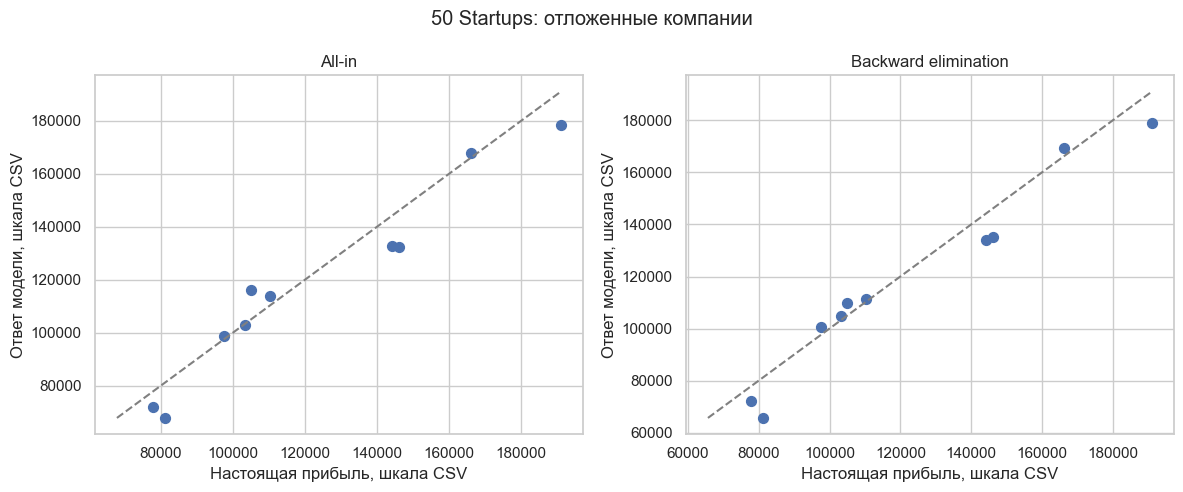

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, predicted, title in zip(axes, [startup_all_prediction, startup_backward_prediction], ['All-in', 'Backward elimination']):
    ax.scatter(ys_test, predicted, s=50)
    low, high = min(ys_test.min(), predicted.min()), max(ys_test.max(), predicted.max())
    ax.plot([low, high], [low, high], '--', color='gray')
    ax.set(title=title, xlabel='Настоящая прибыль, шкала CSV', ylabel='Ответ модели, шкала CSV')
fig.suptitle('50 Startups: отложенные компании')
fig.tight_layout()
save_show(fig, '01_startups_predictions.png')

В каждой панели показаны те же десять отложенных компаний. Ближе к пунктиру — меньшая ошибка. После удаления признаков модель становится проще, но это не обязательно делает все ответы точнее. Сравниваем по таблице ошибок, а не по числу оставшихся столбцов.

## 3. Индивидуальное задание: многомерная регрессия памяти

### 3.1. Прежний набор данных
RCAEval содержит измерения микросервисов Online Boutique во время одного CPU-эксперимента. Используем тот же сценарий из первой работы. Новые сценарии не добавляем. Единицы отдельных показателей в локальном файле не указаны: сохраняем исходные шкалы или явно подписываем деление на миллион.

**Согласование датасета с преподавателем:** ____________________  
**Дата:** ____________________

Читаем сохранённое имя сценария.

In [21]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем локальные метрики и время внесения сбоя.

In [22]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Показываем первые строки и размер таблицы.

In [23]:
display(df.head())
print('Сценарий:', case, '| Сервис:', selection['root_cause_service'], '| Тип сбоя:', selection['fault'])
print('Строк:', len(df), '| Метрик:', df.shape[1] - 1, '| Пропусков:', int(df.isna().sum().sum()))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Сервис: checkoutservice | Тип сбоя: cpu
Строк: 1441 | Метрик: 72 | Пропусков: 4


### 3.2. Отложенные данные
Соседние измерения похожи, поэтому оставляем целые минутные участки для проверки. Внешнее разделение учитывает периоды до и после внесения, чтобы они были представлены в обеих частях. Период и время не входят в признаки регрессии.

Это оценка текущего показателя по другим метрикам в рамках одного эксперимента. Модель не прогнозирует будущее и не проверяется здесь на другом сбое.

Выбираем минутные участки для обучения и проверки.

In [24]:
minute_groups = ((df.time - df.time.min()) // 60).astype(int)
period = (df.time >= inject_time).astype(int)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, period, minute_groups))
print('Обучение:', len(train_idx), '| Проверка:', len(test_idx))

Обучение: 1141 | Проверка: 300


### 3.3. Несколько признаков вместо одного CPU
Продолжаем задачу работы № 8: оцениваем **текущую память checkoutservice**. Теперь рассматриваем CPU, socket, workload, медианную задержку этого сервиса и CPU frontend. Это реальные столбцы прежнего сценария.

Память делим на миллион и не включаем в признаки. Время и период не входят в X. Все пять признаков числовые; категория в этом задании не добавляется искусственно. Подготовка категорий уже проверена в примере State и доступна в том же шаблоне.

Выбираем пять признаков и целевую память.

In [25]:
features = ['checkoutservice_cpu', 'checkoutservice_socket', 'checkoutservice_workload',
            'checkoutservice_latency-50', 'frontend_cpu']
target = 'checkoutservice_mem'
X = df[features].copy()
y = df[target] / 1e6
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = minute_groups.iloc[train_idx]
display(df[features + [target]].isna().sum().rename('Пропуски'))

checkoutservice_cpu           0
checkoutservice_socket        0
checkoutservice_workload      0
checkoutservice_latency-50    0
frontend_cpu                  0
checkoutservice_mem           0
Name: Пропуски, dtype: int64

Пропусков в выбранных метриках нет. Все признаки меняются в течение записи. Сначала рассматриваем связи на обучающих строках, затем оцениваем их вклад в совместную модель.

Рассчитываем корреляции обучения и строим тепловую карту.

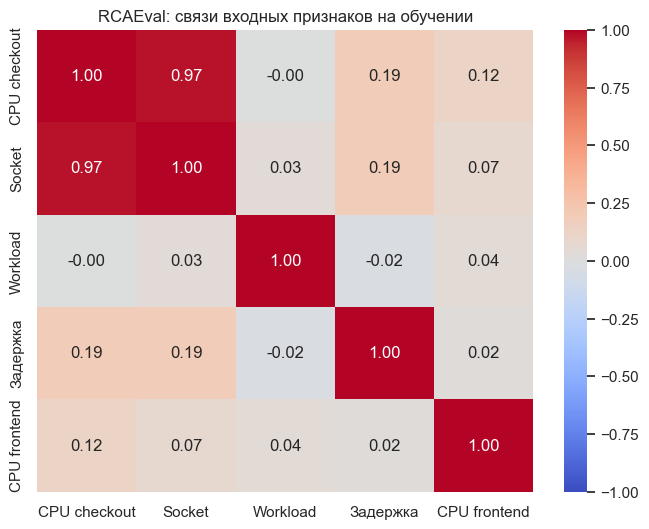

In [26]:
labels = {'checkoutservice_cpu': 'CPU checkout', 'checkoutservice_socket': 'Socket',
          'checkoutservice_workload': 'Workload', 'checkoutservice_latency-50': 'Задержка',
          'frontend_cpu': 'CPU frontend'}
correlations = X_train.corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlations.rename(index=labels, columns=labels), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('RCAEval: связи входных признаков на обучении')
save_show(fig, '02_rca_correlations.png')

Цвет и число показывают, насколько близко меняются два признака. Сильная связь CPU и socket может сделать их совместные коэффициенты менее устойчивыми: они частично несут одну информацию. Корреляция не доказывает причинность, а отсутствие большой корреляции не доказывает независимость.

### 3.4. All-in и значимость коэффициентов
Для RCAEval p-значения рассчитываем с группировкой по минутам, поскольку соседние секундные измерения похожи. Такие оценки всё равно приблизительны: обучающих минутных участков немного, а соседние минуты одного эксперимента тоже могут зависеть друг от друга. Используем p-значения как учебный критерий сокращения модели.

Обучаем модель по всем пяти признакам.

In [27]:
all_model = Pipeline([
    ('prepare', make_preprocessor(features, [])),
    ('regression', LinearRegression())
]).fit(X_train, y_train)
train_ready = all_model.named_steps['prepare'].transform(X_train)
all_ols = fit_ols(train_ready, y_train, groups_train)
print('Обучающих минутных участков:', groups_train.nunique())
display(pd.DataFrame({'Вес': all_ols.params, 'p-значение': all_ols.pvalues}))

Обучающих минутных участков: 20


,Вес,p-значение
const,14.099423,1.321090e-39
checkoutservice_cpu,-0.054647,2.453435e-01
checkoutservice_socket,2.370525,1.832067e-22
checkoutservice_workload,-0.039323,1.151402e-01
checkoutservice_latency-50,-0.043416,9.603214e-02
frontend_cpu,0.011860,2.503845e-01


В таблице вес относится к изменению подготовленного признака на одно стандартное отклонение обучения при фиксированных остальных признаках. Малое p-значение не является доказательством причины изменения памяти. `const` — свободный член, который сохраняется при отборе.

### 3.5. Автоматическое исключение — индивидуальное задание

Обучаем полный пайплайн с backward elimination.

In [28]:
model = make_backward_pipeline(features, alpha=ALPHA)
model.fit(X_train, y_train, regression__groups=groups_train)
selected = model.named_steps['regression']
display(selected.history_)
print('Выбранные признаки:', selected.columns_)

,step,features,max_p,worst,removed
0,1,"checkoutservice_cpu, checkoutservice_socket, c...",2.503845e-01,frontend_cpu,frontend_cpu
1,2,"checkoutservice_cpu, checkoutservice_socket, c...",3.093902e-01,checkoutservice_cpu,checkoutservice_cpu
2,3,"checkoutservice_socket, checkoutservice_worklo...",1.401210e-01,checkoutservice_workload,checkoutservice_workload
3,4,"checkoutservice_socket, checkoutservice_latenc...",1.132957e-01,checkoutservice_latency-50,checkoutservice_latency-50
4,5,checkoutservice_socket,4.188496e-24,checkoutservice_socket,нет


Выбранные признаки: ['checkoutservice_socket']


Показываем коэффициенты и p-значения сокращённой модели.

In [29]:
display(pd.DataFrame({'Вес': selected.result_.params, 'p-значение': selected.result_.pvalues}))

,Вес,p-значение
const,14.099423,6.118204e-39
checkoutservice_socket,2.308812,4.188496e-24


Строим график наибольшего p-значения по шагам.

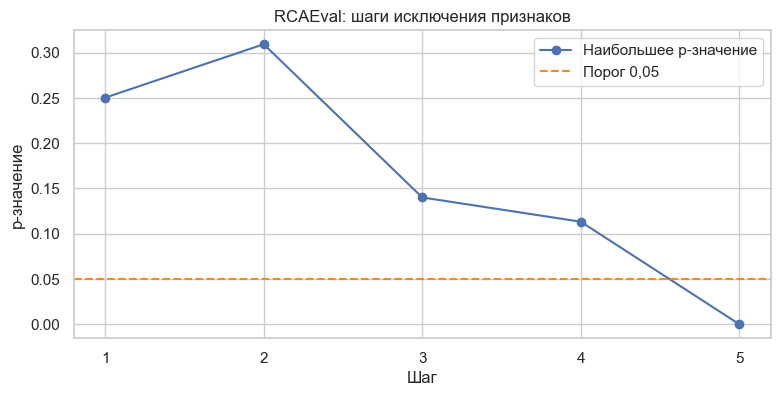

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(selected.history_.step, selected.history_.max_p, marker='o', label='Наибольшее p-значение')
ax.axhline(ALPHA, color='darkorange', linestyle='--', label='Порог 0,05')
ax.set(title='RCAEval: шаги исключения признаков', xlabel='Шаг', ylabel='p-значение',
       xticks=selected.history_.step.to_list())
ax.legend()
save_show(fig, '03_rca_elimination.png')

На каждом шаге точка показывает наибольшее p-значение текущих признаков. Пока оно выше порога, соответствующий признак удаляется. Последняя точка показывает остановку. Число шагов включает последнюю проверку; конкретные имена удалений приведены в таблице.

### 3.6. Итоговая проверка all-in и сокращённой модели

Получаем ответы и сравниваем ошибки на отложенных минутах.

In [31]:
all_prediction = all_model.predict(X_test)
prediction = model.predict(X_test)
mean_prediction = np.full(len(y_test), y_train.mean())
metrics = pd.DataFrame([
    regression_scores(y_test, mean_prediction), regression_scores(y_test, all_prediction),
    regression_scores(y_test, prediction)
], index=['Среднее обучения', 'All-in', 'Backward elimination'])
display(metrics)

,MSE,MAE,R2
Среднее обучения,5.295515,2.289958,-0.063386
All-in,0.052354,0.195353,0.989487
Backward elimination,0.043121,0.184168,0.991341


Все три строки используют одинаковые настоящие ответы и минуты проверки. MSE и MAE меньше у более точной модели. R² может быть отрицательным. Сокращённая модель проверяется после выбора признаков; по тестовой таблице их не возвращаем и не удаляем заново.

Показываем несколько настоящих и оценённых значений памяти.

In [32]:
answers = pd.DataFrame({'row': X_test.index, 'time': df.time.iloc[test_idx].to_numpy(),
                        'actual': y_test.to_numpy(), 'all_in': all_prediction,
                        'backward': prediction, 'baseline': mean_prediction})
display(answers.head(10))

,row,time,actual,all_in,backward,baseline
0,0,1705353846,11.702272,11.792031,11.722841,14.099423
1,1,1705353847,11.706368,11.722323,11.722841,14.099423
2,2,1705353848,11.706368,11.722323,11.722841,14.099423
3,3,1705353849,11.706368,11.722323,11.722841,14.099423
4,4,1705353850,11.706368,11.696115,11.722841,14.099423
5,5,1705353851,11.706368,11.723478,11.722841,14.099423
6,6,1705353852,11.706368,11.705749,11.722841,14.099423
7,7,1705353853,11.706368,11.705701,11.722841,14.099423
8,8,1705353854,11.706368,11.705652,11.722841,14.099423
9,9,1705353855,11.706368,11.705604,11.722841,14.099423


Строим сравнение настоящей памяти и ответов двух моделей.

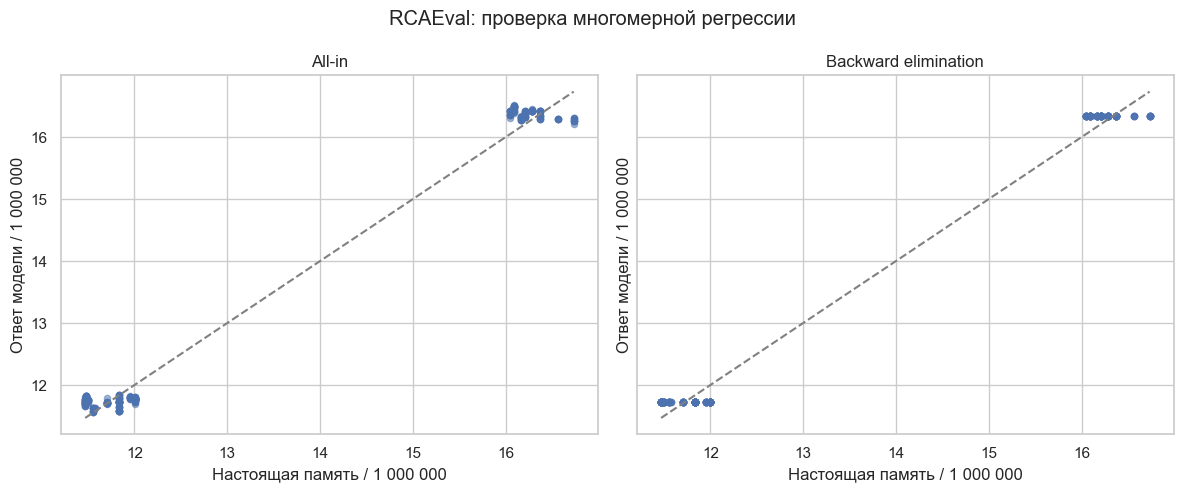

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
low = min(y_test.min(), all_prediction.min(), prediction.min())
high = max(y_test.max(), all_prediction.max(), prediction.max())
for ax, predicted, title in zip(axes, [all_prediction, prediction], ['All-in', 'Backward elimination']):
    ax.scatter(y_test, predicted, s=20, alpha=0.5)
    ax.plot([low, high], [low, high], '--', color='gray')
    ax.set(title=title, xlabel='Настоящая память / 1 000 000', ylabel='Ответ модели / 1 000 000')
fig.suptitle('RCAEval: проверка многомерной регрессии')
fig.tight_layout()
save_show(fig, '04_rca_predictions.png')

Оси двух панелей имеют одну шкалу. Близость точек к пунктиру показывает точность. Можно увидеть, насколько ответы после исключения отличаются от all-in. Картинка относится к полным входным строкам: здесь не пытаемся представить многомерное правило одной прямой по CPU.

Показываем ошибки двух моделей во времени.

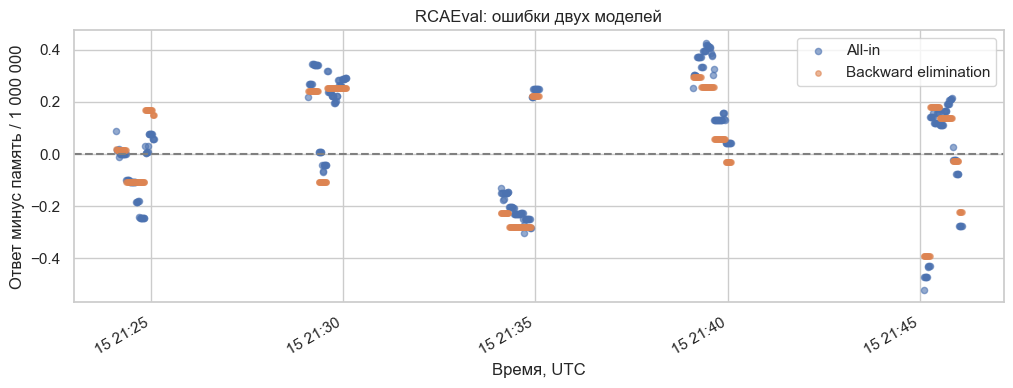

In [34]:
ordered = answers.sort_values('time')
when = pd.to_datetime(ordered.time, unit='s', utc=True)
fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(when, ordered.all_in - ordered.actual, s=20, alpha=0.6, label='All-in')
ax.scatter(when, ordered.backward - ordered.actual, s=15, alpha=0.6, label='Backward elimination')
ax.axhline(0, color='gray', linestyle='--')
ax.set(title='RCAEval: ошибки двух моделей', xlabel='Время, UTC', ylabel='Ответ минус память / 1 000 000')
ax.legend()
fig.autofmt_xdate()
save_show(fig, '05_rca_errors.png')

Положительная ошибка означает завышение памяти, отрицательная — занижение. Цвета относятся к двум моделям на тех же строках. Если точки совпадают, удаление признаков почти не изменило ответы. Разрывы между участками соответствуют выбору минут для проверки.

Сохраняем историю отбора, ответы и простой текст результата.

In [35]:
model_scores = regression_scores(y_test, prediction)
all_scores = regression_scores(y_test, all_prediction)
word = 'ниже' if model_scores['MSE'] < all_scores['MSE'] else 'не ниже'
analysis = (f'Применил общий пайплайн к многомерной регрессии на {case}. Начал с {len(features)} признаков; '
            f'после backward elimination осталось {len(selected.columns_)}: {", ".join(selected.columns_) or "только свободный член"}. '
            f'На {len(y_test)} отложенных строках MAE сокращённой модели = {model_scores["MAE"]:.4f} в миллионах исходных единиц памяти. '
            f'Её MSE {word} MSE модели all-in. Отбор выполнялся только по обучению. '
            'Построил таблицы p-значений, историю удалений и графики ошибок; проверка относится к одному эксперименту.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
selected.history_.to_csv(REPORT / 'elimination_history.csv', index=False)
metrics.to_csv(REPORT / 'regression_metrics.csv', index_label='model')
answers.to_csv(REPORT / 'predictions.csv', index=False)
pd.DataFrame({'coefficient': selected.result_.params, 'pvalue': selected.result_.pvalues}).to_csv(
    REPORT / 'selected_coefficients.csv', index_label='feature')
startup_selected.history_.to_csv(REPORT / 'startups_elimination.csv', index=False)
startup_metrics.to_csv(REPORT / 'startups_metrics.csv', index_label='model')
summary = {'case': case, 'initial_features': features, 'selected_features': selected.columns_,
           'alpha': ALPHA, 'train_rows': len(X_train), 'test_rows': len(X_test),
           'training_clusters': int(groups_train.nunique()), 'pvalue_covariance': 'cluster by minute',
           'target': target, 'target_scale': 'original / 1e6', 'all_in': all_scores, 'backward': model_scores,
           'startup_selected_features': startup_selected.columns_}

Применил общий пайплайн к многомерной регрессии на re2ob_checkoutservice_cpu_1. Начал с 5 признаков; после backward elimination осталось 1: checkoutservice_socket. На 300 отложенных строках MAE сокращённой модели = 0.1842 в миллионах исходных единиц памяти. Её MSE ниже MSE модели all-in. Отбор выполнялся только по обучению. Построил таблицы p-значений, историю удалений и графики ошибок; проверка относится к одному эксперименту.

Сохраняем сведения об исходных файлах и список рисунков.

In [36]:
sources = {'example_url': example_url, 'example_revision': example_revision, 'rcaeval': selection,
           'sha256': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                      for path in [example_path, metrics_path, inject_path]}}
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')
summary['figures'] = sorted(path.name for path in FIGURES.glob('*.png'))
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

923

## 4. Заключение
Научился применять разработанный пайплайн для тиражирования кода и решения разных задач машинного обучения. Повторно использовал подготовку из работы № 7 и расширил её до многомерной регрессии с автоматическим исключением признаков.

Освоил all-in и backward elimination, расчёт p-значений и сравнение ошибок на отложенных строках. На RCAEval оценивал текущую память по нескольким метрикам. История отбора позволила объяснить каждое удаление; меньшее число признаков само по себе не гарантирует лучшие ответы.

## 5. Ответы на контрольные вопросы
**1. Зачем нужен столбец из единиц?**  
Он позволяет подобрать свободный член. В statsmodels OLS он добавляется явно. LinearRegression по умолчанию уже обучает свободный член, поэтому вручную добавлять туда единицы обычно не требуется.

**2. Что такое фиктивная переменная и зачем удалять одну?**  
Это индикатор категории: 1 для выбранного значения и 0 иначе. Если создать все индикаторы одной категории вместе со свободным членом, их сумма будет равна столбцу единиц. Возникнет точная линейная зависимость. Поэтому один индикатор оставляют базовым и не включают в X.

**3. По какому критерию удаляется признак?**  
В этой работе — по наибольшему p-значению выше 0,05 при проверке гипотезы о нулевом коэффициенте. Это условный учебный критерий значимости, а не доказательство ненужности признака в любой модели. Порог задаётся заранее; тестовые ответы в отборе не используются.

**4. Что такое all-in regression?**  
Обучение модели со всеми выбранными входными признаками сразу, без последовательного отбора.

**5. Что такое forward selection?**  
Начинают с простого набора, обычно только со свободного члена. По очереди проверяют добавление каждого ещё не выбранного признака, добавляют лучший по заданному критерию и повторяют, пока улучшение есть.

**6. Что такое bidirectional elimination?**  
Сочетание добавления и удаления: после добавления нового признака снова проверяют, не следует ли удалить ранее выбранный. Все решения принимаются на данных для обучения и подбора.

**7. Как автоматизировать backward elimination?**  
В цикле обучить OLS, найти максимальное p-значение среди признаков, удалить его столбец при превышении порога и заново обучить модель. Остановиться, когда критерий выполнен или признаков не осталось. Константу исключают из списка кандидатов. В ноутбуке это реализовано функцией `backward_elimination` и шагом `BackwardOLS` в Pipeline.

## 6. Источники
- Методичка `Practicum_AI_Methods.pdf`, раздел этой лабораторной работы.
- [Учебные таблицы Machine Learning A–Z](https://github.com/murphymv/Machine-Learning-A-Z/tree/66d3cdbd8a19102c54750d8e8bd834845c7eedef) — копии CSV примеров; они не заменяют индивидуальный датасет мониторинга.
- [RCAEval](https://huggingface.co/datasets/phamquiluan/RCAEval).
- [scikit-learn: ColumnTransformer](https://scikit-learn.org/1.7/modules/generated/sklearn.compose.ColumnTransformer.html).
- [scikit-learn: LinearRegression](https://scikit-learn.org/1.7/modules/generated/sklearn.linear_model.LinearRegression.html).
- [statsmodels: OLS](https://www.statsmodels.org/v0.14.6/generated/statsmodels.regression.linear_model.OLS.html).
- [statsmodels: расчёт ошибок с учётом групп](https://www.statsmodels.org/v0.14.6/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html).